# Music Recommendation — Content-based Only

This notebook builds a **content-based** music recommender using TF-IDF on combined text (song, artist, genre, lyrics) and cosine similarity.

In [1]:
import os 
print(os.path.abspath("initial_music_recommender_mj.ipynb"))

C:\Users\M!KK_J\AI & Society Project\initial_music_recommender_mj.ipynb


In [2]:

# Imports
import numpy as np
import pandas as pd
import joblib, os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

C:\Users\M!KK_J\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [3]:
# Load dataset (mapping 'text' column to lyrics)
DATA_PATH = "spotify_millsongdata_with_genres.csv"
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip().lower() for c in df.columns]
# map 'text' -> 'lyrics' if present
if 'text' in df.columns and 'lyrics' not in df.columns:
    df = df.rename(columns={'text':'lyrics'})
expected = {'artist','song','genre','lyrics'}
missing = expected - set(df.columns)
if missing:
    raise ValueError(f"Missing columns in CSV: {missing}. Required: {expected}")
print("Loaded rows:", len(df))
df.head(5)

Loaded rows: 57650


,artist,song,link,lyrics,genre
0,ABBA,Ahe's My Kind Of Girl,/a/abba/ahes+my+kind+of+girl_20598417.html,"Look at her face, it's a wonderful face \r\nA...",Pop
1,ABBA,"Andante, Andante",/a/abba/andante+andante_20002708.html,"Take it easy with me, please \r\nTouch me gen...",Pop
2,ABBA,As Good As New,/a/abba/as+good+as+new_20003033.html,I'll never know why I had to go \r\nWhy I had...,Pop
3,ABBA,Bang,/a/abba/bang_20598415.html,Making somebody happy is a question of give an...,Pop
4,ABBA,Bang-A-Boomerang,/a/abba/bang+a+boomerang_20002668.html,Making somebody happy is a question of give an...,Pop


In [4]:

# Basic preprocessing and combined text
df['artist'] = df['artist'].astype(str).fillna('').str.strip()
df['song']   = df['song'].astype(str).fillna('').str.strip()
df['genre']  = df['genre'].astype(str).fillna('').str.strip()
df['lyrics'] = df['lyrics'].astype(str).fillna('').str.strip()
df['text'] = (df['song'] + ' ' + df['artist'] + ' ' + df['genre'] + ' ' + df['lyrics']).str.lower()
df = df.reset_index(drop=True)
df['song_id'] = df.index.map(lambda x: f"S{str(x).zfill(5)}")
print("Prepared text — example:")
print(df['text'].iloc[0][:300])

Prepared text — example:
ahe's my kind of girl abba pop look at her face, it's a wonderful face  
and it means something special to me  
look at the way that she smiles when she sees me  
how lucky can one fellow be?  
  
she's just my kind of girl, she makes me feel fine  
who could ever believe that she could be min


In [5]:

# TF-IDF vectorization (fit)
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_text = tfidf.fit_transform(df['text'])
print("TF-IDF matrix shape:", X_text.shape)
joblib.dump(tfidf, 'tfidf_vectorizer_contentonly.pkl')
print("Saved tfidf_vectorizer_contentonly.pkl")

TF-IDF matrix shape: (57650, 5000)
Saved tfidf_vectorizer_contentonly.pkl


In [6]:

# Content-based recommender functions
from sklearn.metrics.pairwise import linear_kernel
songid_to_idx = {sid: idx for idx, sid in enumerate(df['song_id'])}

def recommend_by_song(song_id, top_n=10):
    if song_id not in songid_to_idx:
        raise ValueError("song_id not found")
    idx = songid_to_idx[song_id]
    sims = cosine_similarity(X_text[idx], X_text).flatten()
    sims[idx] = -1
    top_idx = np.argpartition(-sims, range(min(top_n, len(sims))))[:min(top_n, len(sims))]
    top_sorted = top_idx[np.argsort(-sims[top_idx])]
    return df.iloc[top_sorted].copy().assign(score = sims[top_sorted])

def recommend_by_text(seed_text, top_n=10):
    vec = tfidf.transform([seed_text.lower()])
    sims = cosine_similarity(vec, X_text).flatten()
    top_idx = np.argpartition(-sims, range(min(top_n, len(sims))))[:min(top_n, len(sims))]
    top_sorted = top_idx[np.argsort(-sims[top_idx])]
    return df.iloc[top_sorted].copy().assign(score=sims[top_sorted])

example_song = df.loc[0,'song_id']
print('Example seed song:', example_song, df.loc[0,['song','artist','genre']].to_dict())
recommend_by_song(example_song, top_n=5)

Example seed song: S00000 {'song': "Ahe's My Kind Of Girl", 'artist': 'ABBA', 'genre': 'Pop'}


,artist,song,link,lyrics,genre,text,song_id,score
23119,Air Supply,What Kind Of Girl,/a/air+supply/what+kind+of+girl_20004834.html,What kind of man is enough to begin to underst...,Unknown,what kind of girl air supply unknown what kind...,S23119,0.539103
44380,The Monkees,The Kind Of Girl I Could Love,/m/monkees/the+kind+of+girl+i+could+love_20095...,"Girl, you look mighty good to me \r\nAnd I kn...",Unknown,the kind of girl i could love the monkees unkn...,S44380,0.497977
52857,The Temptations,Girl (Why You Wanna Make Me Blue),/t/temptations/girl+why+you+wanna+make+me+blue...,"I love you girl, with all my heart and soul \...",Unknown,girl (why you wanna make me blue) the temptati...,S52857,0.398788
24736,The Beatles,Girl,/b/beatles/girl_10026474.html,Is there anybody going to listen to my story ...,Rock,girl the beatles rock is there anybody going t...,S24736,0.389699
9367,John Denver,Don't Be Kind,/j/john+denver/dont+be+kind_20821819.html,"You've been sweet, you've been good \r\nI've ...",Unknown,don't be kind john denver unknown you've been ...,S09367,0.387192


In [7]:

# Example: recommend by custom text (e.g., "upbeat pop dance")
seed = "upbeat pop dance"
print("Seed text:", seed)
recommend_by_text(seed, top_n=5)

Seed text: upbeat pop dance


,artist,song,link,lyrics,genre,text,song_id,score
19861,U2,Pop Muzik,/u/u2/pop+muzik_10161069.html,"Muzik \r\nPop, pop pop, muzik \r\n \r\nPop ...",Unknown,"pop muzik u2 unknown muzik \r\npop, pop pop, ...",S19861,0.714869
18176,Roxette,Make My Head Go Pop,/r/roxette/make+my+head+go+pop_20118798.html,"I don't know much about you, but I pretty sure...",Unknown,make my head go pop roxette unknown i don't kn...,S18176,0.672316
52205,Steve Miller Band,Dance Dance Dance,/s/steve+miller+band/dance+dance+dance_2018393...,"My grandpa, he's 95 \r\nAnd he keeps on danci...",Unknown,dance dance dance steve miller band unknown my...,S52205,0.668583
24633,Beach Boys,"Dance, Dance, Dance",/b/beach+boys/dance+dance+dance_20014009.html,After six hours of school I've had enough for ...,Unknown,"dance, dance, dance beach boys unknown after s...",S24633,0.666062
56615,Wilson Phillips,Dance Dance Dance,/w/wilson+phillips/dance+dance+dance_10188128....,After six hours of school I've had enough for ...,Unknown,dance dance dance wilson phillips unknown afte...,S56615,0.663648


In [8]:

# Save top-5 recommendations for the first 10 songs to a CSV (example output)
outputs = []
for i in range(min(10, len(df))):
    sid = df.loc[i,'song_id']
    recs = recommend_by_song(sid, top_n=5)
    for rank, (_, r) in enumerate(recs.iterrows(), start=1):
        outputs.append({'seed_song_id': sid, 'seed_title': df.loc[i,'song'], 'rank': rank, 'rec_song_id': r['song_id'], 'rec_title': r['song'], 'rec_artist': r['artist'], 'rec_genre': r['genre'], 'score': r['score']})
outdf = pd.DataFrame(outputs)
outdf.to_csv('example_recommendations_top5_for_first10.csv', index=False)
print('Wrote example_recommendations_top5_for_first10.csv')

Wrote example_recommendations_top5_for_first10.csv


In [9]:

# Quick utility: show recommendations neatly for a given song index (human-friendly)
def pretty_show(song_idx, top_n=5):
    sid = df.loc[song_idx, 'song_id']
    print("Seed:", sid, "-", df.loc[song_idx,['song','artist','genre']].to_dict())
    print(recommend_by_song(sid, top_n=top_n)[['song_id','song','artist','genre','score']].to_string(index=False))

for i in range(min(3, len(df))):
    pretty_show(i, top_n=5)
    print('---')

Seed: S00000 - {'song': "Ahe's My Kind Of Girl", 'artist': 'ABBA', 'genre': 'Pop'}
song_id                              song          artist   genre    score
 S23119                 What Kind Of Girl      Air Supply Unknown 0.539103
 S44380     The Kind Of Girl I Could Love     The Monkees Unknown 0.497977
 S52857 Girl (Why You Wanna Make Me Blue) The Temptations Unknown 0.398788
 S24736                              Girl     The Beatles    Rock 0.389699
 S09367                     Don't Be Kind     John Denver Unknown 0.387192
---
Seed: S00001 - {'song': 'Andante, Andante', 'artist': 'ABBA', 'genre': 'Pop'}
song_id                song         artist   genre    score
 S48822         Sing A Song Point Of Grace Unknown 0.494453
 S26224 Let It All Be Music       Boney M. Unknown 0.473766
 S04271           Applejack   Dolly Parton Unknown 0.410842
 S45324         I Am A Song    Neil Sedaka Unknown 0.405204
 S26919                Sing     Carpenters Unknown 0.400618
---
Seed: S00002 - {'song

# Music Recommendation UI........................

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

# MAIN UI ELEMENTS
input_type = widgets.Dropdown(
    options=[
        "Search by Song Name",
        "Search by Song ID",
        "Search by Artist Name",   # NEW MODE
        "Custom Text Query"
    ],
    value="Search by Song Name",
    description="Mode:"
)

user_input = widgets.Text(
    placeholder="Enter song name, artist name, ID, or description...",
    description="Input:",
    layout=widgets.Layout(width='60%')
)

num_results = widgets.IntSlider(
    value=10, min=3, max=20, step=1,
    description="Top N:"
)

recommend_button = widgets.Button(
    description="Recommend",
    button_style="success",
    tooltip="Click to get recommendations"
)

random_button = widgets.Button(
    description="🎲 Random Song Recommend",
    button_style="info",
    tooltip="Pick a random song and recommend"
)

output = widgets.Output()

# -----------------------------------
# HANDLERS
# -----------------------------------

def recommend_from_ui(_):
    with output:
        clear_output()
        mode = input_type.value
        text = user_input.value.strip()
        n = num_results.value
        
        if text == "":
            print("⚠️ Please enter something.")
            return
        
        # MODE 1: search by song name
        if mode == "Search by Song Name":
            matches = df[df['song'].str.contains(text, case=False, na=False)]
            if len(matches) == 0:
                print("❌ No song found with that name.")
                return
            sid = matches.iloc[0]['song_id']
            print(f"🎵 Matched Song: {sid} – {matches.iloc[0]['song']}")
            display(recommend_by_song(sid, top_n=n)[['song_id','song','artist','genre','score']])
        
        # MODE 2: search by song ID
        elif mode == "Search by Song ID":
            if text not in df['song_id'].values:
                print("❌ Invalid song ID.")
                return
            print(f"🎵 Seed Song: {text} – {df.loc[df['song_id']==text, 'song'].values[0]}")
            display(recommend_by_song(text, top_n=n)[['song_id','song','artist','genre','score']])

        # MODE 3: search by ARTIST NAME
        elif mode == "Search by Artist Name":
            matches = df[df['artist'].str.contains(text, case=False, na=False)]
            if len(matches) == 0:
                print("❌ No songs found for that artist.")
                return

            seed_row = matches.iloc[0]
            sid = seed_row['song_id']
            print(f"🎤 Artist Match: {seed_row['artist']}")
            print(f"🎵 Using song: {sid} – {seed_row['song']}")
            display(recommend_by_song(sid, top_n=n)[['song_id','song','artist','genre','score']])

        # MODE 4: custom text query
        elif mode == "Custom Text Query":
            print(f"📝 Query: {text}")
            display(recommend_by_text(text, top_n=n)[['song_id','song','artist','genre','score']])


def recommend_random(_):
    with output:
        clear_output()
        # Pick random song
        idx = np.random.randint(0, len(df))
        sid = df.loc[idx, 'song_id']
        title = df.loc[idx, 'song']
        print(f"🎲 Random Seed: {sid} – {title}")
        display(recommend_by_song(sid, top_n=num_results.value)[['song_id','song','artist','genre','score']])


# CONNECT BUTTONS
recommend_button.on_click(recommend_from_ui)
random_button.on_click(recommend_random)

# DISPLAY UI
display(input_type, user_input, num_results, recommend_button, random_button, output)


Dropdown(description='Mode:', options=('Search by Song Name', 'Search by Song ID', 'Search by Artist Name', 'C…

Text(value='', description='Input:', layout=Layout(width='60%'), placeholder='Enter song name, artist name, ID…

IntSlider(value=10, description='Top N:', max=20, min=3)

Button(button_style='success', description='Recommend', style=ButtonStyle(), tooltip='Click to get recommendat…

Button(button_style='info', description='🎲 Random Song Recommend', style=ButtonStyle(), tooltip='Pick a random…

Output()

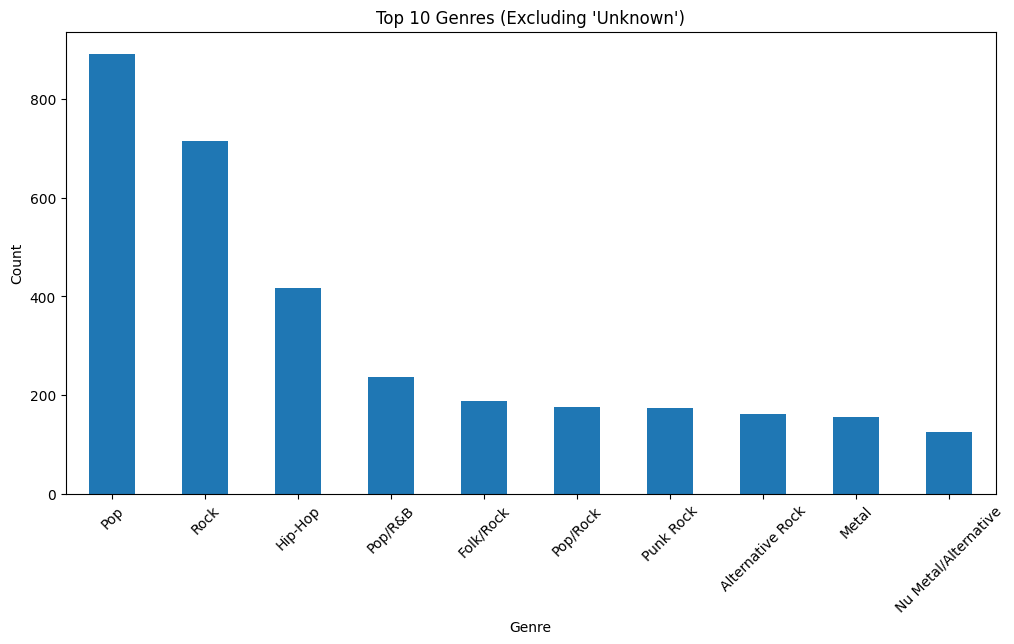

In [11]:
df[df['genre'] != 'Unknown']['genre'].value_counts().head(10).plot(kind='bar', figsize=(12,6))
plt.title("Top 10 Genres (Excluding 'Unknown')")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()



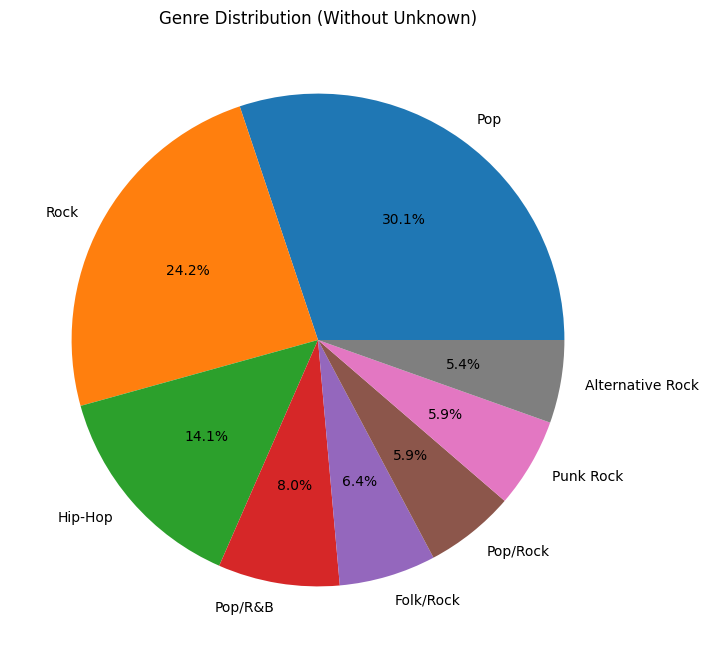

In [12]:
df[df['genre'] != 'Unknown']['genre'].value_counts().head(8).plot(
    kind='pie', autopct='%1.1f%%', figsize=(8,8)
)
plt.title("Genre Distribution (Without Unknown)")
plt.ylabel("")
plt.show()


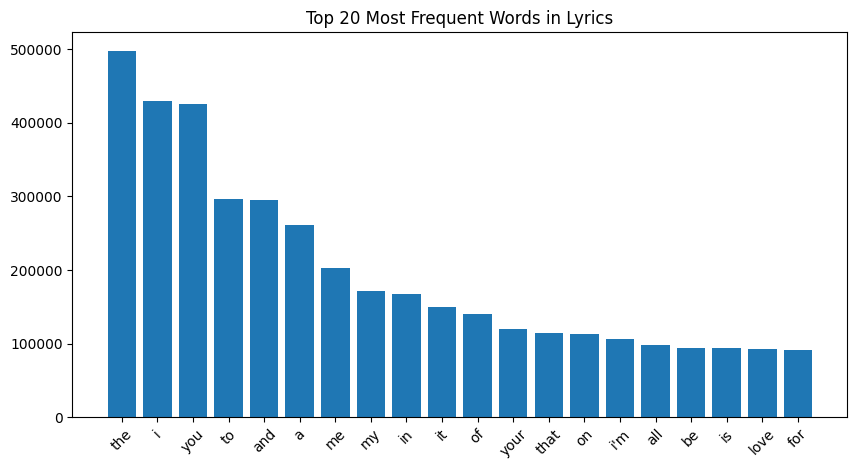

In [13]:
from collections import Counter
import re

all_words = " ".join(df['lyrics']).lower()
all_words = re.findall(r"[a-z']+", all_words)
common = Counter(all_words).most_common(20)

words = [w for w,c in common]
counts = [c for w,c in common]

plt.figure(figsize=(10,5))
plt.bar(words, counts)
plt.xticks(rotation=45)
plt.title("Top 20 Most Frequent Words in Lyrics")
plt.show()


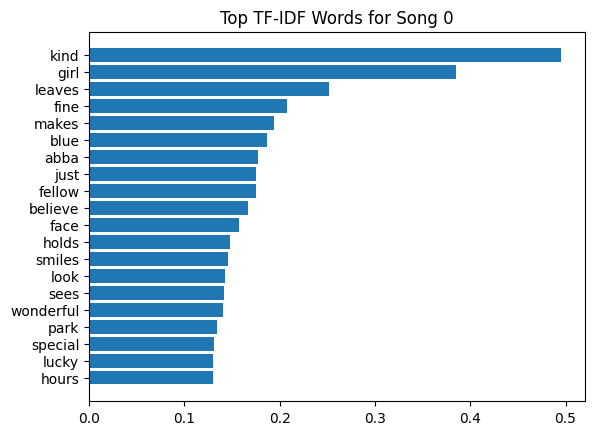

In [14]:
feature_names = tfidf.get_feature_names_out()
row = X_text[0].toarray().ravel()
top_idx = row.argsort()[-20:]
plt.barh(feature_names[top_idx], row[top_idx])
plt.title("Top TF-IDF Words for Song 0")
plt.show()


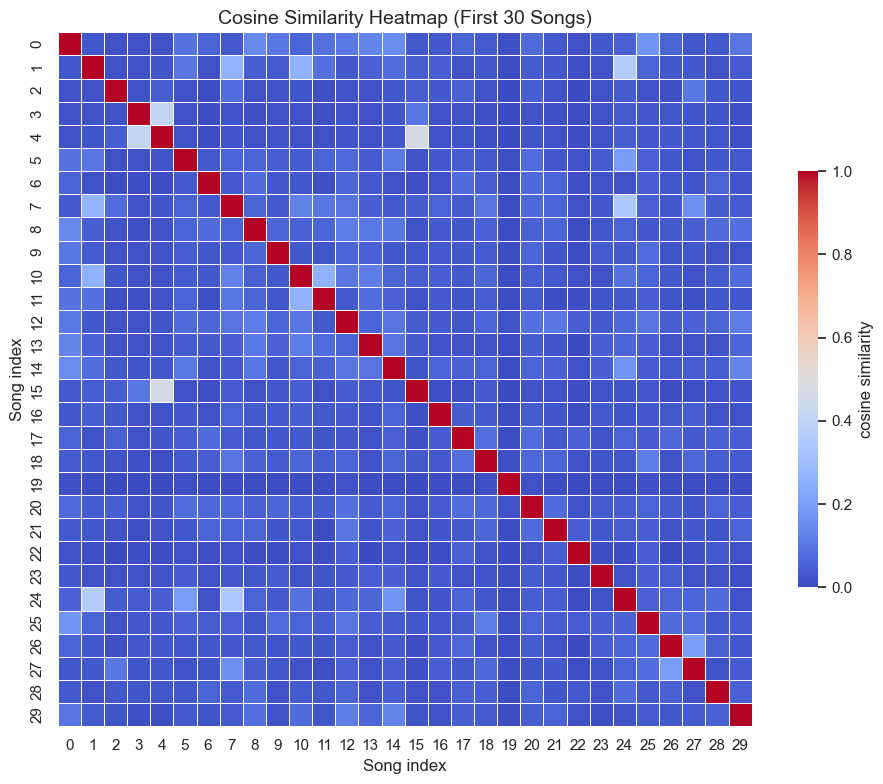

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# choose N (20 was used before); try 30 or 40 for clearer patterns
N = 30
Xsmall = X_text[:N]
sim = cosine_similarity(Xsmall)  # NxN matrix

plt.figure(figsize=(10,8))
sns.set(style="white")
ax = sns.heatmap(sim,
                 cmap="coolwarm",      # pleasant continuous colormap
                 vmin=0, vmax=1,      # similarity in [0,1]
                 square=True,
                 linewidths=0.4,      # subtle grid lines
                 linecolor='white',
                 cbar_kws={'shrink':0.6, 'label':'cosine similarity'})

ax.set_title(f"Cosine Similarity Heatmap (First {N} Songs)", fontsize=14)
ax.set_xlabel("Song index")
ax.set_ylabel("Song index")
plt.tight_layout()
plt.savefig("heatmap_clean.png", dpi=300)
plt.show()
